# 07 — Time series clustering of monthly unit series

**Question.** Which tracts / UTBs have similar monthly series of recorded bulletins 2022–2025, either in
**level** (how many bulletins per month: `value`) or in **shape** (when the series rises and falls,
regardless of level: `profile`)? Descriptive; no inference.

**Method.** k-means (MacQueen 1967; Lloyd's algorithm) on the 48-month series of every unit with ≥ 1 bulletin
in 2022–2025 (units with none get cluster −1; project choice):

* **(a) profile** — each unit's series z-normalised over its own 48 months (`scipy.stats.zscore`, mean 0,
  sd 1). For z-normalised series the squared Euclidean distance equals $2T(1-r)$ (T = 48, r = Pearson
  correlation), so k-means on them groups series by correlation.
* **(b) value** — the raw monthly counts.

k ∈ 2…8 is chosen by the largest Calinski–Harabasz pseudo-F (Caliński & Harabasz 1974;
`sklearn.metrics.calinski_harabasz_score`, the rule of Esri's tool); the silhouette
(Rousseeuw 1987; `sklearn.metrics.silhouette_score`) is reported beside it. Cluster ids are re-numbered
1…k in increasing order of the mean bulletins per unit (2022–2025 total).

**Library.** `sklearn.cluster.KMeans(n_clusters=k, n_init=10, random_state=SEED)` (scikit-learn 1.7).

**Esri differences.** Esri's "How Time Series Clustering works" uses k-medoids with a correlation distance
(1 − r) for profile clustering and reports medoids; here it is k-means on z-scored series (same ordering of
pairwise distances, but centres are means, not medoids, and k-means minimises squared distance). This is the
library approximation available in the environment (`tslearn` / k-medoids implementations are not installed).
`docs/METHODS.md` §4 states k ∈ 2…10; this notebook uses 2…8 as specified for this run.

**Citations.** MacQueen, J. (1967). Some methods for classification and analysis of multivariate
observations. *Proc. 5th Berkeley Symp.* 1. Caliński, T. & Harabasz, J. (1974). A dendrite method for cluster
analysis. *Communications in Statistics* 3(1). Rousseeuw, P.J. (1987). Silhouettes. *J. Comput. Appl. Math.* 20.

In [1]:
import time
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import zscore
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, silhouette_score

from crime.core.config import NOTEBOOK_OUTPUTS_DIR
from crime.data import GROUPS, load_units, unit_counts

import _mapstyle as ms  # notebooks/_mapstyle.py: basemap, overlay, graticule, scale bar, legends

SEED = 20221
K_RANGE = range(2, 9)
SUPPORTS = ("tract", "utb")
MODES = ("profile", "value")
LAB = {"tract": "census tracts", "utb": "UTBs"}
OUT = NOTEBOOK_OUTPUTS_DIR / "07_time_series_clustering"
OUT.mkdir(parents=True, exist_ok=True)
T0 = time.time()
ms.setup()
units = {s: load_units(s) for s in SUPPORTS}
cube = {(s, g): unit_counts(s, g, freq="M").reindex(units[s]["unit_id"]) for s in SUPPORTS for g in GROUPS}
months = cube["tract", "all"].columns
print(len(months), "months:", months[0].date(), "..", months[-1].date())

48 months: 2022-01-01 .. 2025-12-01


In [2]:
def cluster(s, g, mode):
    Y = cube[s, g]
    active = Y.sum(axis=1) > 0
    X = Y[active].to_numpy(dtype=float)
    if mode == "profile":
        sd = X.std(axis=1)
        ok = sd > 0                       # a constant non-zero series has no shape
        X = zscore(X[ok], axis=1)
        idx = Y.index[active][ok]
    else:
        idx = Y.index[active]
    scores, fits = [], {}
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        fits[k] = km
        scores.append(dict(support=s, group=g, mode=mode, k=k, n_units=len(X),
                           calinski_harabasz=calinski_harabasz_score(X, km.labels_),
                           silhouette=silhouette_score(X, km.labels_, random_state=SEED) if len(X) > k else np.nan))
    sc = pd.DataFrame(scores)
    kbest = int(sc.loc[sc.calinski_harabasz.idxmax(), "k"])
    raw = fits[kbest].labels_
    total = Y.loc[idx].sum(axis=1).to_numpy()
    order = pd.Series(total).groupby(raw).mean().sort_values().index   # ascending mean bulletins per unit
    remap = {old: new + 1 for new, old in enumerate(order)}
    lab = pd.Series(-1, index=Y.index, name="cluster")
    lab.loc[idx] = [remap[c] for c in raw]
    return sc, kbest, lab

scores, best, labels = [], {}, {}
for s in SUPPORTS:
    for g in GROUPS:
        for m in MODES:
            sc, kb, lab = cluster(s, g, m)
            scores.append(sc); best[s, g, m] = kb; labels[s, g, m] = lab
scores = pd.concat(scores, ignore_index=True)
scores.to_csv(OUT / "k_selection_scores.csv", index=False)
pd.DataFrame({f"{s}_{g}_{m}": lab for (s, g, m), lab in labels.items() if s == "tract"}).to_csv(OUT / "labels_tract.csv")
pd.DataFrame({f"{s}_{g}_{m}": lab for (s, g, m), lab in labels.items() if s == "utb"}).to_csv(OUT / "labels_utb.csv")
print(f"{len(scores)} k-means fits in {time.time() - T0:.0f} s")

168 k-means fits in 159 s


## Choice of k (all groups)

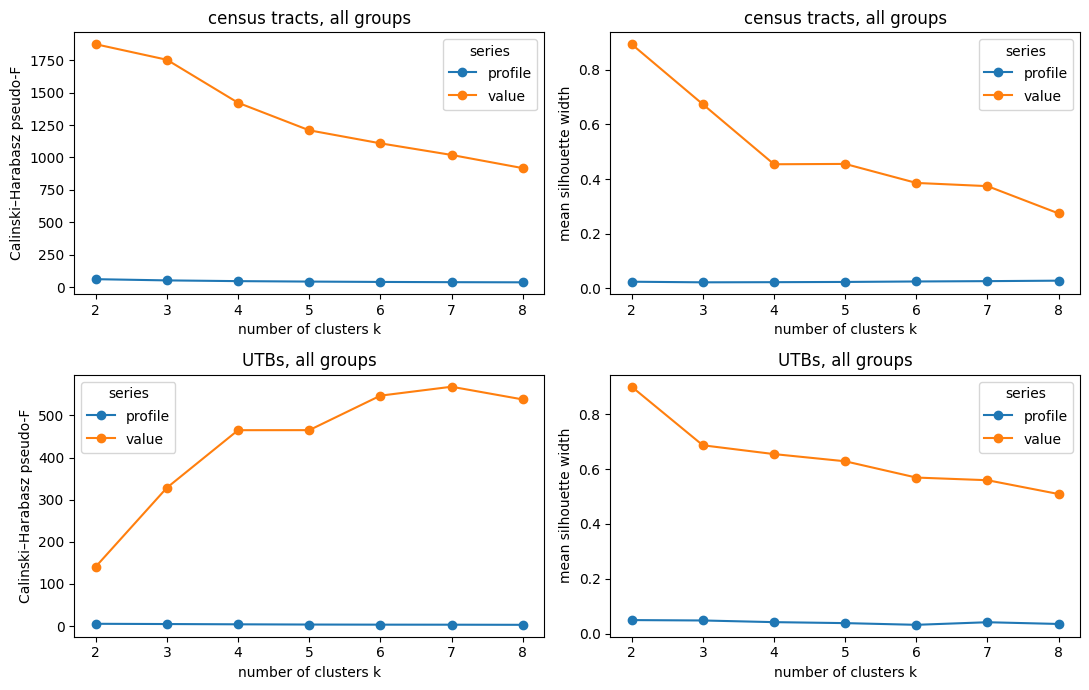

calinski_harabasz                            silhouette         \
support             tract               utb               tract          
mode              profile     value profile    value    profile  value   
k                                                                        
2                  60.826  1874.154   5.542  141.041      0.025  0.893   
3                  51.415  1754.307   4.946  328.438      0.023  0.673   
4                  45.741  1422.365   4.288  464.957      0.023  0.454   
5                  42.280  1209.889   3.753  465.073      0.024  0.455   
6                  39.520  1109.373   3.477  546.925      0.026  0.386   
7                  37.694  1019.699   3.383  568.076      0.027  0.374   
8                  36.581   918.005   3.093  537.939      0.029  0.274   

                        
support     utb         
mode    profile  value  
k                       
2         0.049  0.900  
3         0.048  0.687  
4         0.041  0.655  
5         0.038  0.628  
6         0.032  0.569  
7         0.041  0.559  
8         0.035  0.509

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for i, s in enumerate(SUPPORTS):
    for m in MODES:
        sc = scores.query("support == @s and group == 'all' and mode == @m")
        axes[i, 0].plot(sc.k, sc.calinski_harabasz, marker="o", label=m)
        axes[i, 1].plot(sc.k, sc.silhouette, marker="o", label=m)
    axes[i, 0].set_ylabel("Calinski–Harabasz pseudo-F")
    axes[i, 1].set_ylabel("mean silhouette width")
    for ax in axes[i]:
        ax.set_xlabel("number of clusters k"); ax.set_title(f"{LAB[s]}, all groups"); ax.legend(title="series")
fig.tight_layout(); fig.savefig(OUT / "k_selection_all.png", dpi=300)
plt.show(); plt.close(fig)
scores.query("group == 'all'").pivot_table(index="k", columns=["support", "mode"], values=["calinski_harabasz", "silhouette"]).round(3)

## Clusters — all groups

Maps of the cluster id (1 = lowest mean bulletins per unit; −1 = no bulletin 2022–2025) and the cluster
mean series: for `value` the mean monthly count per unit; for `profile` the mean z-score of the series
(the shape the cluster shares) and, below, the mean monthly count of the same clusters for scale.

In [4]:
def summary(s, g, m):
    lab = labels[s, g, m]; Y = cube[s, g]
    tot = Y.sum(axis=1)
    d = pd.DataFrame({"cluster": lab, "total": tot, "area_km2": units[s].set_index("unit_id")["area_km2"].reindex(lab.index)})
    out = d.groupby("cluster").agg(n_units=("total", "size"), mean_bulletins_per_unit=("total", "mean"),
                                   total_bulletins=("total", "sum"), total_area_km2=("area_km2", "sum")).reset_index()
    return out.assign(support=s, group=g, mode=m, k=best[s, g, m])

summ = pd.concat([summary(s, g, m) for s in SUPPORTS for g in GROUPS for m in MODES], ignore_index=True)
summ.to_csv(OUT / "cluster_summary.csv", index=False)
summ.query("group == 'all'")

,cluster,n_units,mean_bulletins_per_unit,total_bulletins,total_area_km2,support,group,mode,k
0,-1,186,0.000000,0,61.553996,tract,all,profile,2
1,1,1188,40.085017,47621,413.353312,tract,all,profile,2
2,2,1218,49.456486,60238,319.892429,tract,all,profile,2
3,-1,186,0.000000,0,61.553996,tract,all,value,2
4,1,2383,37.788082,90049,710.993183,tract,all,value,2
5,2,23,774.347826,17810,22.252558,tract,all,value,2
38,-1,5,0.000000,0,3.322271,utb,all,profile,2
39,1,44,576.977273,25387,284.815989,utb,all,profile,2
40,2,44,1874.363636,82472,507.214188,utb,all,profile,2
41,-1,5,0.000000,0,3.322271,utb,all,value,7


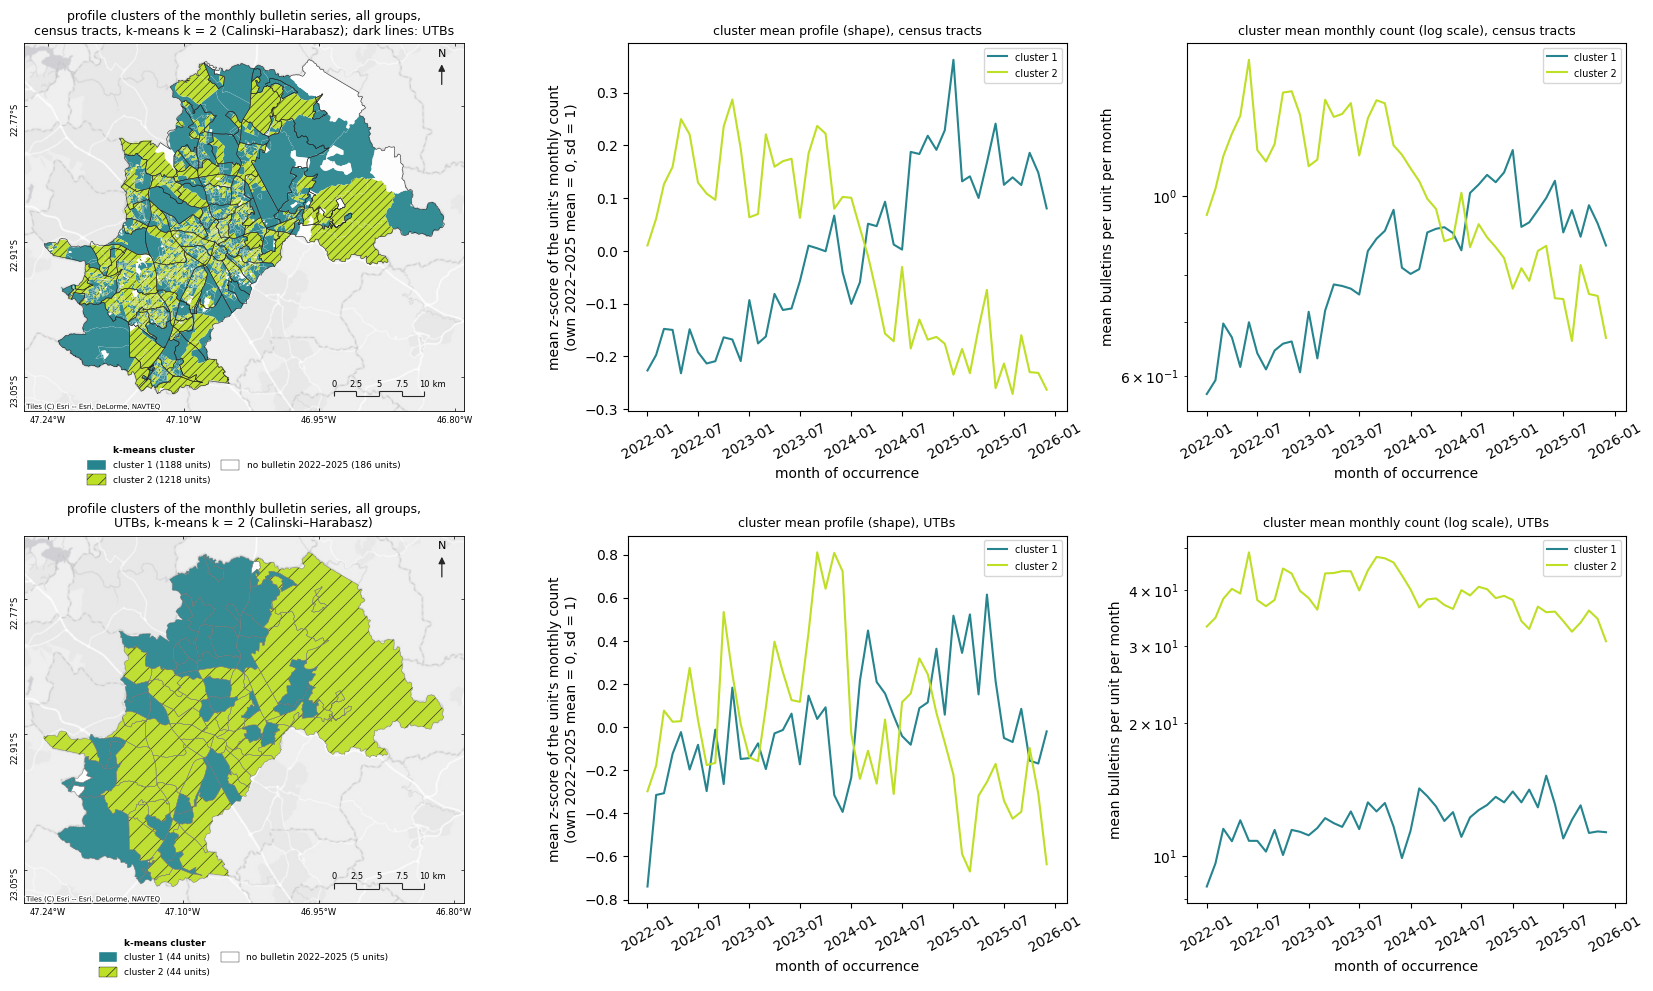

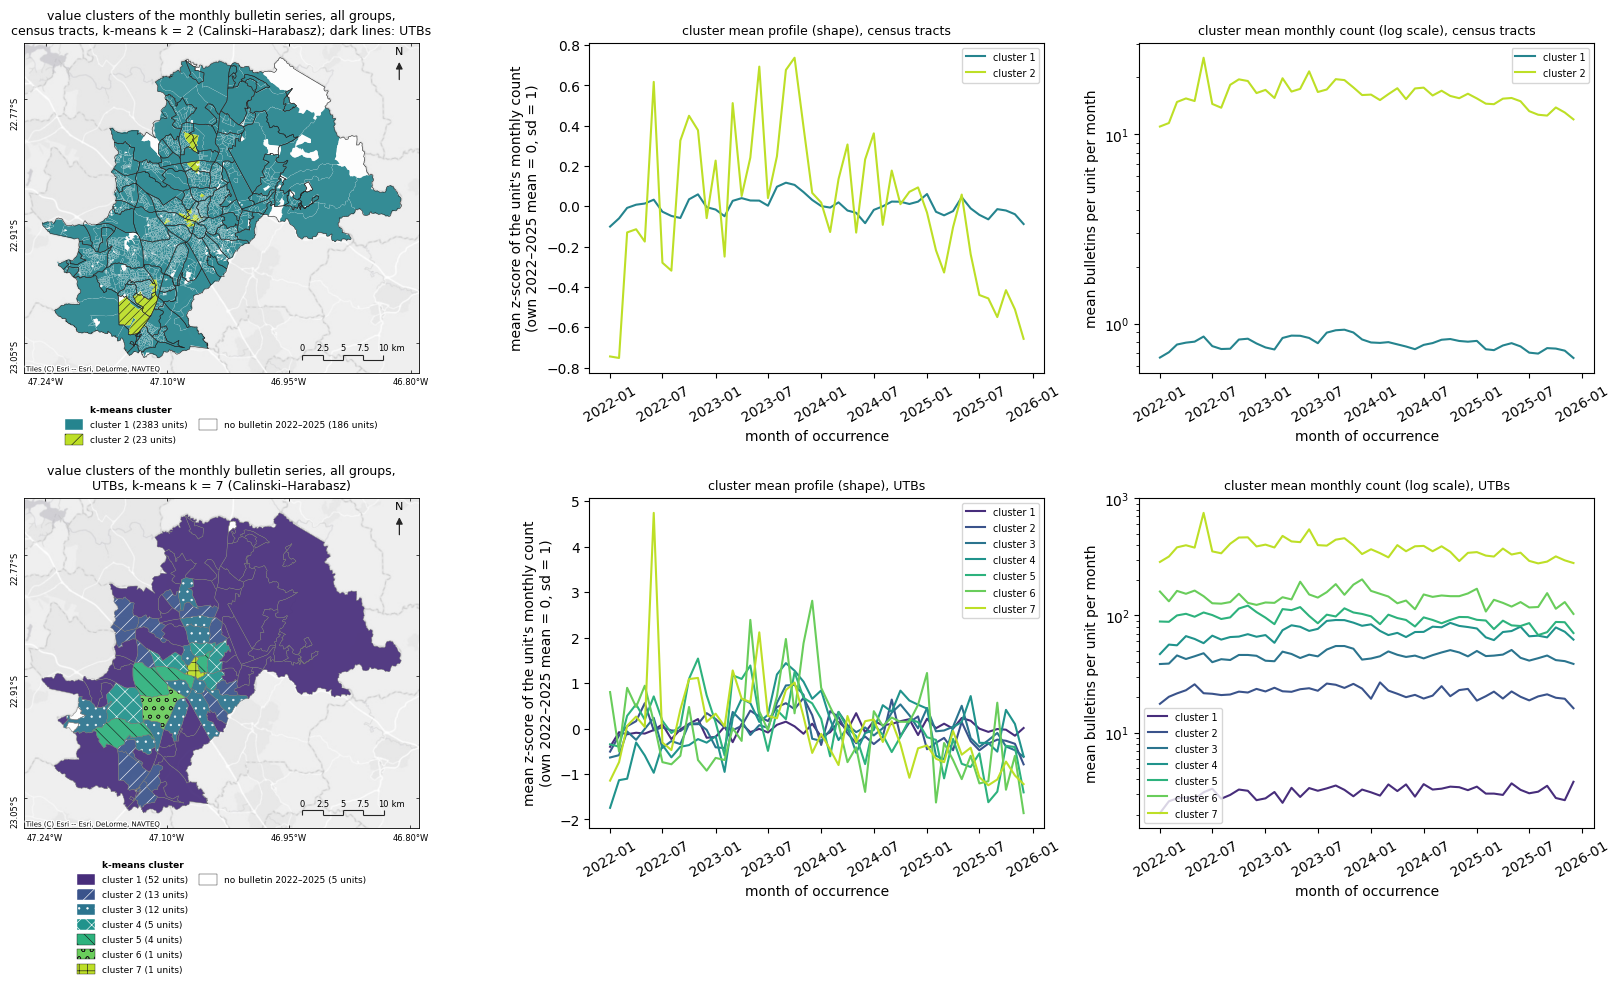

In [5]:
cmap = plt.get_cmap("viridis")
CLUSTER_HATCH = ["", "//", "..", "xx", "\\\\", "oo", "++", "--"]
for m in MODES:
    fig, axes = plt.subplots(2, 3, figsize=(17, 10), gridspec_kw={"width_ratios": [1.2, 1, 1]})
    for i, s in enumerate(SUPPORTS):
        lab = labels[s, "all", m]; k = best[s, "all", m]
        cols = {c: cmap(c / k * 0.9) for c in range(1, k + 1)}; cols[-1] = "white"
        ax = axes[i, 0]
        # colour and hatch per cluster (hatch keeps neighbouring viridis shades apart)
        style = {c: (cols[c], CLUSTER_HATCH[(c - 1) % len(CLUSTER_HATCH)]) for c in range(1, k + 1)}
        style[-1] = ("white", "")
        tract = s == "tract"
        ms.plot_categories(ax, units[s], lab.reindex(units[s]["unit_id"]).to_numpy(), style,
                           hatch_repeat=2 if tract else 1, linewidth=0.05 if tract else 0.3,
                           edgecolor="white" if tract else "0.45")
        ms.decorate(ax, units[s].crs, overlay=units["utb"] if tract else None)
        vc = lab.value_counts()
        ms.category_legend(ax, {"k-means cluster": [(f"cluster {c}", *style[c]) for c in range(1, k + 1)],
                                "": [("no bulletin 2022–2025", *style[-1])]},
                           counts={**{f"cluster {c}": f"{vc.get(c, 0)} units" for c in range(1, k + 1)},
                                   "no bulletin 2022–2025": f"{vc.get(-1, 0)} units"},
                           loc="upper center", bbox=(0.5, -0.07), fontsize=6.5)
        ax.set_title(f"{m} clusters of the monthly bulletin series, all groups,\n{LAB[s]}, k-means k = {k} (Calinski–Harabasz)" + ("; dark lines: UTBs" if s == "tract" else ""), fontsize=9)
        Y = cube[s, "all"]
        Z = pd.DataFrame(np.nan, index=Y.index, columns=Y.columns)
        act = (Y.sum(axis=1) > 0) & (Y.std(axis=1) > 0)
        Z.loc[act] = zscore(Y.loc[act].to_numpy(dtype=float), axis=1)
        for c in range(1, k + 1):
            sel = lab.index[lab == c]
            axes[i, 1].plot(months, Z.loc[sel].mean(), color=cols[c], label=f"cluster {c}")
            axes[i, 2].plot(months, Y.loc[sel].mean(), color=cols[c], label=f"cluster {c}")
        axes[i, 1].set_ylabel("mean z-score of the unit's monthly count\n(own 2022–2025 mean = 0, sd = 1)")
        axes[i, 1].set_title(f"cluster mean profile (shape), {LAB[s]}", fontsize=9)
        axes[i, 2].set_ylabel("mean bulletins per unit per month")
        axes[i, 2].set_yscale("log")
        axes[i, 2].set_title(f"cluster mean monthly count (log scale), {LAB[s]}", fontsize=9)
        for ax in axes[i, 1:]:
            ax.set_xlabel("month of occurrence"); ax.legend(fontsize=7); ax.tick_params(axis="x", labelrotation=30)
    fig.tight_layout(); fig.savefig(OUT / f"clusters_all_{m}.png", dpi=300)
    plt.show(); plt.close(fig)

## Other groups (table only)

In [6]:
other = summ.query("group != 'all' and cluster != -1").copy()
tbl = (other.assign(desc=lambda d: d.cluster.astype(str) + ": " + d.n_units.astype(str) + " units, "
                    + d.mean_bulletins_per_unit.round(1).astype(str) + "/unit")
       .groupby(["support", "group", "mode", "k"])["desc"].agg(" | ".join).reset_index())
tbl.to_csv(OUT / "other_groups_clusters.csv", index=False)
pd.set_option("display.max_colwidth", 200)
tbl

,support,group,mode,k,desc
0,tract,bodily_harm,profile,2,"1: 1593 units, 3.8/unit | 2: 117 units, 4.4/unit"
1,tract,bodily_harm,value,2,"1: 1647 units, 3.1/unit | 2: 63 units, 22.7/unit"
2,tract,drug,profile,3,"1: 760 units, 4.3/unit | 2: 54 units, 4.6/unit | 3: 96 units, 5.1/unit"
3,tract,drug,value,2,"1: 908 units, 4.0/unit | 2: 2 units, 203.0/unit"
4,tract,property,profile,2,"1: 1180 units, 32.6/unit | 2: 1188 units, 43.8/unit"
5,tract,property,value,2,"1: 2352 units, 32.9/unit | 2: 16 units, 821.0/unit"
6,tract,traffic,profile,3,"1: 1040 units, 4.6/unit | 2: 78 units, 4.9/unit | 3: 209 units, 5.4/unit"
7,tract,traffic,value,2,"1: 1239 units, 3.3/unit | 2: 88 units, 25.1/unit"
8,tract,violent,profile,2,"1: 344 units, 1.4/unit | 2: 19 units, 1.6/unit"
9,tract,violent,value,2,"1: 347 units, 1.4/unit | 2: 16 units, 1.8/unit"


In [7]:
# numbers quoted in the Findings cell
print({k: v for k, v in best.items()})
print(summ.query("group == 'all'").to_string(index=False))
print(f"runtime {time.time() - T0:.0f} s")

{('tract', 'all', 'profile'): 2, ('tract', 'all', 'value'): 2, ('tract', 'property', 'profile'): 2, ('tract', 'property', 'value'): 2, ('tract', 'bodily_harm', 'profile'): 2, ('tract', 'bodily_harm', 'value'): 2, ('tract', 'traffic', 'profile'): 3, ('tract', 'traffic', 'value'): 2, ('tract', 'drug', 'profile'): 3, ('tract', 'drug', 'value'): 2, ('tract', 'violent', 'profile'): 2, ('tract', 'violent', 'value'): 2, ('utb', 'all', 'profile'): 2, ('utb', 'all', 'value'): 7, ('utb', 'property', 'profile'): 2, ('utb', 'property', 'value'): 6, ('utb', 'bodily_harm', 'profile'): 2, ('utb', 'bodily_harm', 'value'): 2, ('utb', 'traffic', 'profile'): 2, ('utb', 'traffic', 'value'): 3, ('utb', 'drug', 'profile'): 2, ('utb', 'drug', 'value'): 3, ('utb', 'violent', 'profile'): 2, ('utb', 'violent', 'value'): 2}
 cluster  n_units  mean_bulletins_per_unit  total_bulletins  total_area_km2 support group    mode  k
      -1      186                 0.000000                0       61.553996   tract   all 

## Findings

*Numbers from the cells above (seed 20221, `n_init=10`); CSVs in `outputs/nb/07_time_series_clustering/`.*

- **Units clustered.** 186 tracts (61.6 km²) and 5 UTBs (3.3 km²) have no bulletin in 2022–2025 and get
  cluster −1; 2,406 tracts and 88 UTBs are clustered.
- **Choice of k.** Calinski–Harabasz picks **k = 2** for every tract run except the traffic and drug profiles
  (k = 3), and for every UTB profile run; on UTB values it picks k = 7 (all groups), 6 (property), 3 (traffic,
  drug), 2 (bodily harm, violent). On tracts the pseudo-F falls monotonically from k = 2, so "k = 2" means
  "no better split was found", not two well-separated groups.
- **Profile (shape) clusters are weak.** The silhouette of the profile solutions is 0.02–0.05 for every k
  (tracts 0.025 at k = 2; UTBs 0.049): z-scored monthly series of single tracts are dominated by noise,
  and the clusters are a partition of a continuum. They still separate two opposite **trends**: tract
  cluster 1 (1,188 tracts) went from 9,115 bulletins in 2022 to 13,675 in 2025 (+50 %), tract cluster 2
  (1,218 tracts) from 17,492 to 11,277 (−36 %). On UTBs, profile cluster 1 (44 UTBs, 577 bulletins per UTB)
  rose from 5,661 to 6,713 and cluster 2 (44 UTBs, 1,874 per UTB) fell from 20,946 to 18,239. The falling
  cluster is the busier one at both scales. The 2025 values may be low because of reporting lag
  (`docs/METHODS.md`, limitations).
- **Value (level) clusters isolate the extreme units.** On tracts, k = 2 puts 23 tracts (22 km²; mean 774
  bulletins per tract; 17,810 bulletins = 16.5 % of all) apart from the other 2,383 (mean 38). The UTB
  solution (k = 7 by CH, silhouette 0.56) is a ranking of levels: *Centro* is alone in cluster 7
  (18,062 bulletins on 3.1 km²) and *Jd. Santa Lúcia/ V. União/ Jd. do Lago* alone in cluster 6 (6,856).
  K-means on raw counts sorts units by size of the count; it adds little to a ranked list.
- **Other groups** (table above) behave the same way: k = 2–3, value clusters split off a handful of units
  with high counts (e.g. drug on tracts: 2 tracts with a mean of 203 bulletins vs 908 tracts with a mean of 4.0).
- **Method caveat.** This is k-means on z-scored series (squared Euclidean = 2T(1 − r)), the scikit-learn
  approximation of Esri's k-medoids on correlation distance; centres are means, not medoids.